# Batch Quality, Equipment Reliability and Commercial Results

**Final notebook for the capstone.** It follows the same eleven sections as the React dashboard, so every figure can be checked in both places.

- Each chart is labelled **Univariate** (one variable), **Bivariate** (two) or **Multivariate** (three or more).
- Each section ends with a summary block whose numbers are computed from the data, not typed in.
- Identifiers are masked to their last four characters.
- Random seed 42. Time split: train 2007 to 2021, validation 2022 to 2023, test 2024 to 2026.
- The notebook reads the same `bqp` package as the pipeline. Model results are read from `reports/`, and the last section checks that the two agree.

**Contents:** 0 Setup and data · 1 Batch failure · 2 Maintenance and equipment · 3 Classifier and predictor · 4 Process control · 5 Receivables · 6 Margin and discounts · 7 Inventory and forecast · 8 Cost and suppliers · 9 Risk score · 10 Consistency check

## 0. Setup and data

In [1]:
import os, sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy.stats import chi2_contingency
from sklearn.metrics import roc_curve, precision_recall_curve, auc, confusion_matrix

warnings.filterwarnings("ignore")
ROOT = Path(os.environ.get("BQP_ROOT", Path.cwd().parent)).resolve()
sys.path.insert(0, str(ROOT / "src"))
from bqp import data, cleaning, features, reliability, process_control, commercial, modeling, config

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
REPORTS, TABLES = ROOT / "reports", ROOT / "reports" / "tables"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 80
PAL = ["#6366F1", "#14B8A6", "#F59E0B", "#8B5CF6", "#0EA5E9", "#F43F5E", "#94A3B8"]

def mask(value):
    """Show only the last four characters of an identifier."""
    text = str(value)
    return "..." + text[-4:] if len(text) > 4 else text

def chart(kind, title):
    """Start a labelled chart: kind is Univariate, Bivariate or Multivariate."""
    display(Markdown(f"**[{kind}] {title}**"))

def summary(points):
    """A summary block for the section, built from computed values."""
    body = "\n".join(f"> - {p}" for p in points)
    display(Markdown("> **Summary of this section**\n" + body))

def pct(x, d=1):
    return f"{100 * x:.{d}f}%"

raw = data.load_all()
inventory = cleaning.build_inventory(raw["inventory"])
batches, register_batch = cleaning.build_batches(raw["batch"], raw["maintenance"])
sales, register_sales = cleaning.build_sales(raw["sales"], inventory)
batches["batch_failed"] = batches["batch_failed"].astype(int)
summary_json = json.loads((REPORTS / "summary.json").read_text())
predictor = json.loads((REPORTS / "predictor.json").read_text())
print(f"Batches {len(batches):,} | sales lines {len(sales):,} | inventory movements {len(inventory):,}")
print(f"Batch failure rate {pct(batches.batch_failed.mean(), 2)} (dashboard figure {summary_json['failure_rate_pct']:.2f}%)")

Batches 60,000 | sales lines 150,000 | inventory movements 162,000
Batch failure rate 3.12% (dashboard figure 3.12%)


**[Univariate] Share of missing values by batch field**

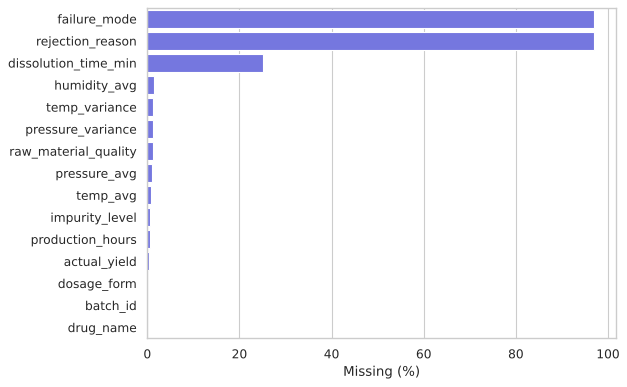

**[Univariate] Batches per production year**

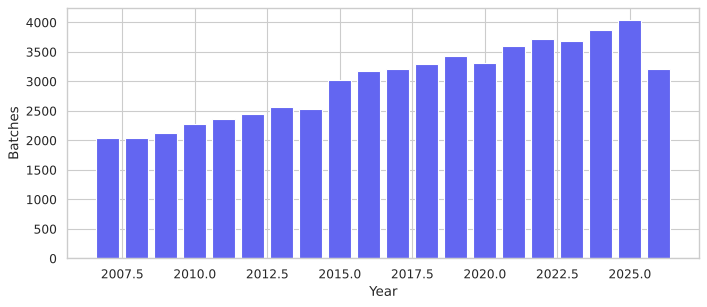

**[Univariate] Quality register: result of each consistency check**

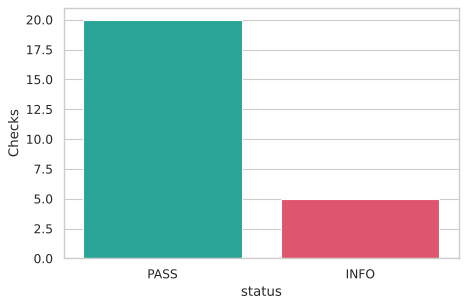

> **Summary of this section**
> - 60,000 batches run from 2007 to 2026; the largest missing share is 96.9% (failure_mode).
> - Of 25 consistency checks, 20 pass, 0 fail and 5 are information rows.

In [2]:
chart("Univariate", "Share of missing values by batch field")
miss = batches.isna().mean().sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=miss.values * 100, y=miss.index, color=PAL[0], ax=ax)
ax.set_xlabel("Missing (%)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

chart("Univariate", "Batches per production year")
per_year = batches.groupby("year").size()
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(per_year.index.astype(int), per_year.values, color=PAL[0])
ax.set_xlabel("Year"); ax.set_ylabel("Batches")
plt.tight_layout(); plt.show()

chart("Univariate", "Quality register: result of each consistency check")
reg = pd.read_csv(TABLES / "quality_register.csv")
counts = reg["status"].value_counts()
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values, palette=[PAL[1], PAL[5], PAL[4]][:len(counts)], ax=ax)
ax.set_ylabel("Checks")
plt.tight_layout(); plt.show()
summary([
    f"{len(batches):,} batches run from {int(batches.year.min())} to {int(batches.year.max())}; the largest missing share is {pct(miss.iloc[0])} ({miss.index[0]}).",
    f"Of {len(reg)} consistency checks, {int(counts.get('PASS', 0))} pass, {int(counts.get('FLAG', 0))} fail and {int(counts.get('INFO', 0))} are information rows.",
])

## 1. Batch failure: where failures occur

**[Univariate] Failure rate by dosage form (95% Wilson interval)**

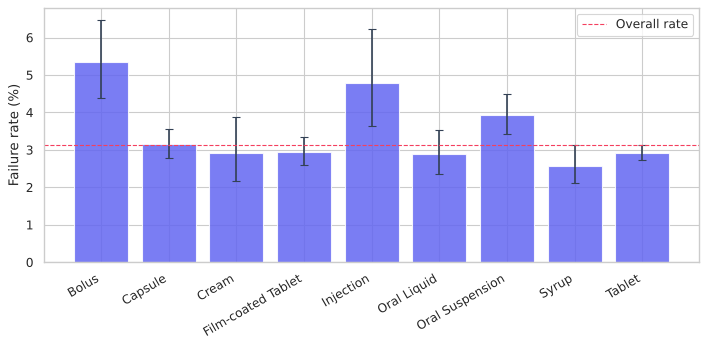

**[Univariate] Failure rate by manufacturing section**

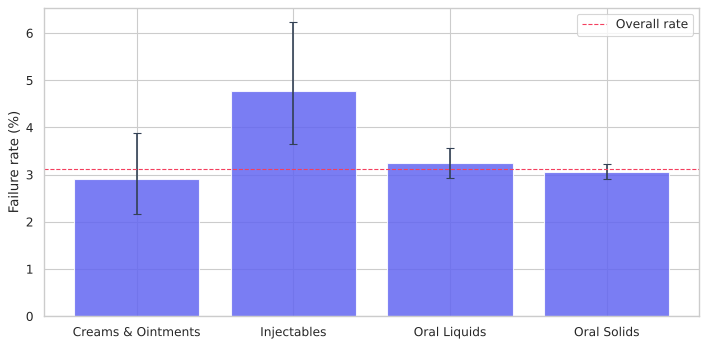

**[Univariate] Failure rate by maintenance status**

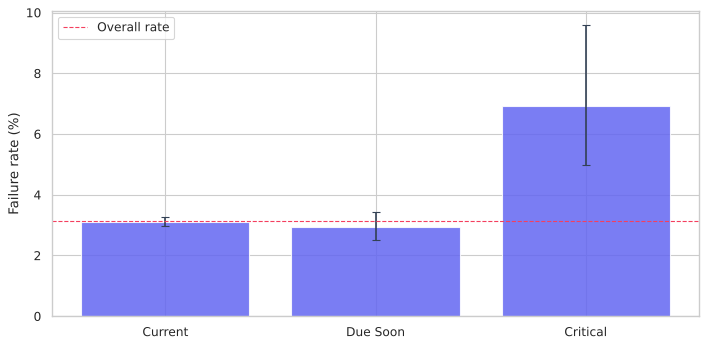

**[Univariate] Failure rate by equipment age band**

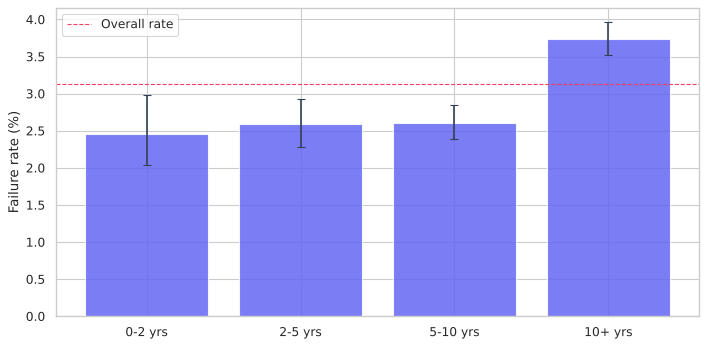

**[Univariate] Failure rate by operator experience band**

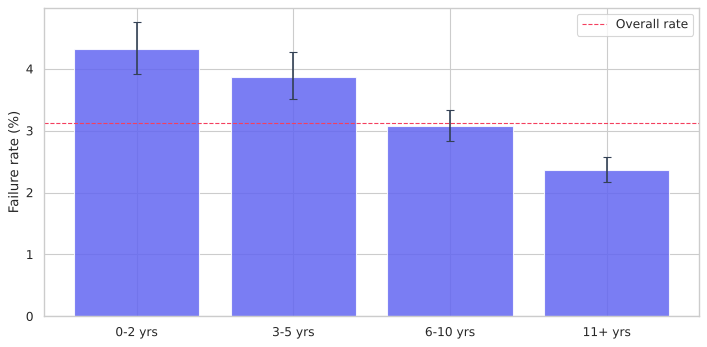

**[Univariate] Distribution of average temperature**

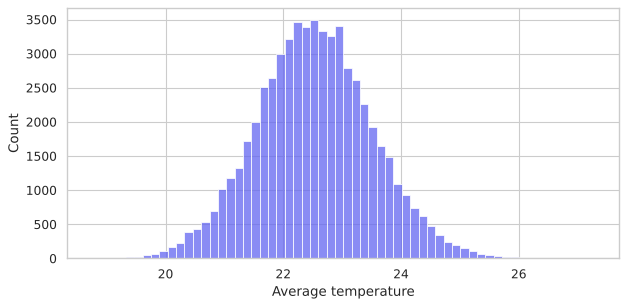

**[Univariate] Distribution of operator experience (years)**

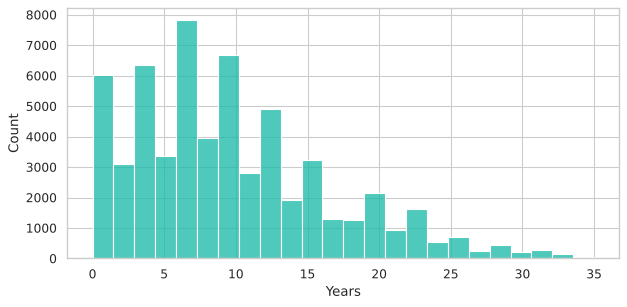

**[Bivariate] Failure rate by production year**

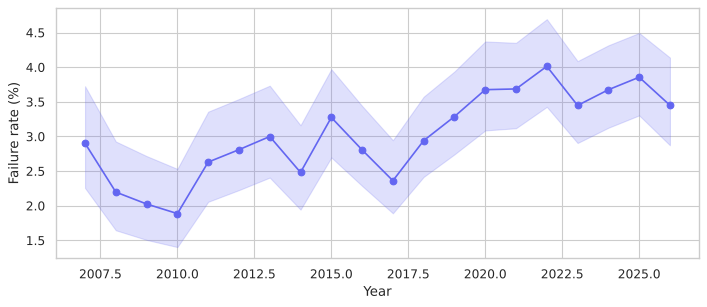

**[Bivariate] Average temperature by batch outcome**

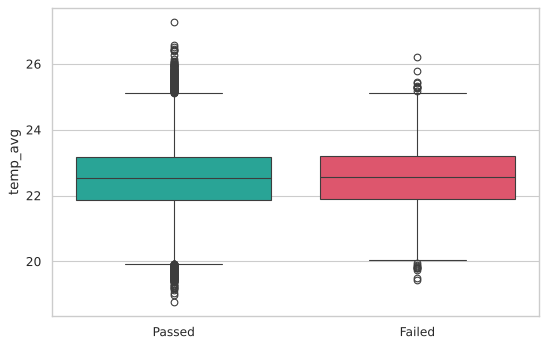

**[Bivariate] Production hours by batch outcome**

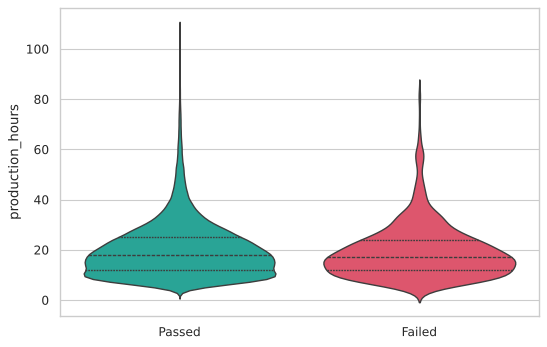

**[Bivariate] Average temperature against average pressure (4,000 random batches)**

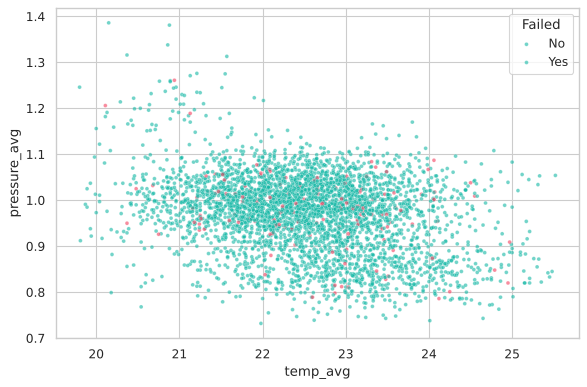

**[Multivariate] Failure rate by dosage form and maintenance status**

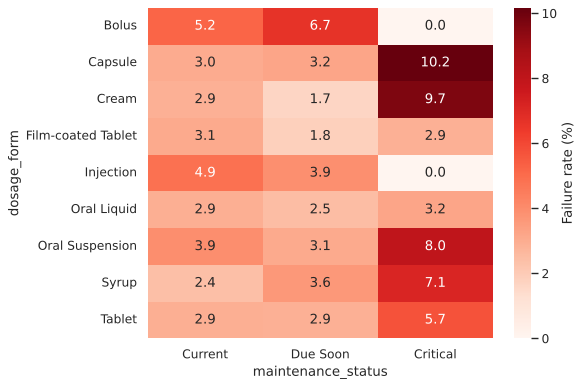

**[Multivariate] Failure rate by operator band, one line per section**

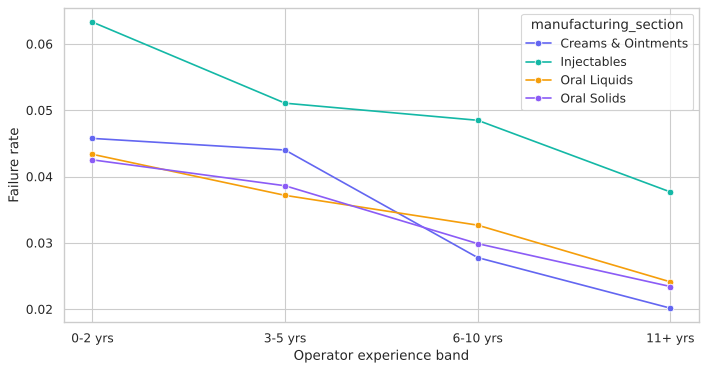

**[Multivariate] Correlation between numeric process readings and failure**

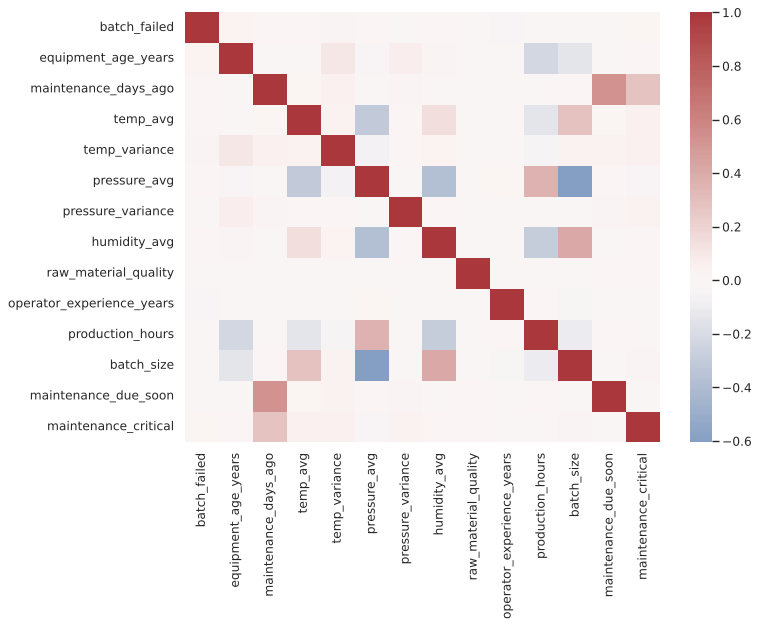

**[Multivariate] Strength of association for each factor (-log10 p-value of chi-square test)**

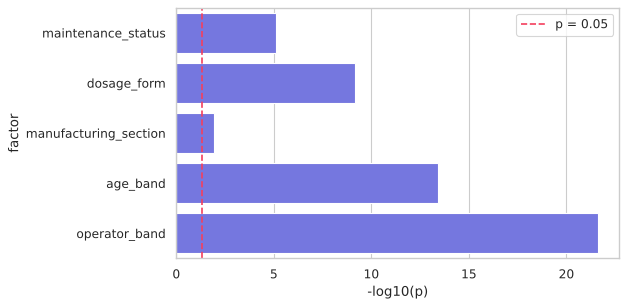

> **Summary of this section**
> - Operator experience band spans 2.4% to 4.3% failure, the widest range of any factor shown.
> - Dosage form ranges from 2.6% to 5.3%; the highest is Bolus.
> - The strongest factor by chi-square test is operator_band (p = 2.4e-22).

In [3]:
def failure_by(column, order=None):
    g = batches.groupby(column).agg(n=("batch_failed", "size"), f=("batch_failed", "sum")).reset_index()
    g["rate"] = g.f / g.n
    g["low"], g["high"] = reliability.wilson_interval(g.f.values, g.n.values)
    if order is not None:
        g = g.set_index(column).loc[order].reset_index()
    return g

def rate_bar(column, title, order=None, rotate=0):
    chart("Univariate", title)
    g = failure_by(column, order)
    fig, ax = plt.subplots(figsize=(9, 4.5))
    x = np.arange(len(g))
    ax.bar(x, g.rate * 100, color=PAL[0], alpha=0.85)
    ax.errorbar(x, g.rate * 100, yerr=[(g.rate - g.low) * 100, (g.high - g.rate) * 100], fmt="none", ecolor="#334155", capsize=4)
    ax.axhline(batches.batch_failed.mean() * 100, color=PAL[5], ls="--", lw=1, label="Overall rate")
    ax.set_xticks(x); ax.set_xticklabels(g[column].astype(str), rotation=rotate, ha="right" if rotate else "center")
    ax.set_ylabel("Failure rate (%)"); ax.legend()
    plt.tight_layout(); plt.show()
    return g

g_dosage = rate_bar("dosage_form", "Failure rate by dosage form (95% Wilson interval)", rotate=30)
g_section = rate_bar("manufacturing_section", "Failure rate by manufacturing section")
g_maint = rate_bar("maintenance_status", "Failure rate by maintenance status", order=["Current", "Due Soon", "Critical"])
g_age = rate_bar("age_band", "Failure rate by equipment age band")
g_oper = rate_bar("operator_band", "Failure rate by operator experience band")

chart("Univariate", "Distribution of average temperature")
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(batches.temp_avg, bins=60, color=PAL[0], ax=ax)
ax.set_xlabel("Average temperature"); plt.tight_layout(); plt.show()

chart("Univariate", "Distribution of operator experience (years)")
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(batches.operator_experience_years, bins=24, color=PAL[1], ax=ax)
ax.set_xlabel("Years"); plt.tight_layout(); plt.show()

chart("Bivariate", "Failure rate by production year")
yr = failure_by("year")
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(yr.year, yr.rate * 100, marker="o", color=PAL[0])
ax.fill_between(yr.year, yr.low * 100, yr.high * 100, alpha=0.2, color=PAL[0])
ax.set_xlabel("Year"); ax.set_ylabel("Failure rate (%)")
plt.tight_layout(); plt.show()

chart("Bivariate", "Average temperature by batch outcome")
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=batches, x="batch_failed", y="temp_avg", palette=[PAL[1], PAL[5]], ax=ax)
ax.set_xticklabels(["Passed", "Failed"]); ax.set_xlabel("")
plt.tight_layout(); plt.show()

chart("Bivariate", "Production hours by batch outcome")
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.violinplot(data=batches, x="batch_failed", y="production_hours", palette=[PAL[1], PAL[5]], inner="quartile", ax=ax)
ax.set_xticklabels(["Passed", "Failed"]); ax.set_xlabel("")
plt.tight_layout(); plt.show()

chart("Bivariate", "Average temperature against average pressure (4,000 random batches)")
samp = batches.sample(4000, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(7.5, 5))
sns.scatterplot(data=samp, x="temp_avg", y="pressure_avg", hue="batch_failed", palette={0: PAL[1], 1: PAL[5]}, s=12, alpha=0.6, ax=ax)
ax.legend(title="Failed", labels=["No", "Yes"])
plt.tight_layout(); plt.show()

chart("Multivariate", "Failure rate by dosage form and maintenance status")
hm = batches.pivot_table(index="dosage_form", columns="maintenance_status", values="batch_failed", aggfunc="mean") * 100
fig, ax = plt.subplots(figsize=(7.5, 5))
sns.heatmap(hm, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Failure rate (%)"}, ax=ax)
plt.tight_layout(); plt.show()

chart("Multivariate", "Failure rate by operator band, one line per section")
lines = batches.groupby(["manufacturing_section", "operator_band"]).batch_failed.mean().reset_index()
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.lineplot(data=lines, x="operator_band", y="batch_failed", hue="manufacturing_section", marker="o", palette=PAL, ax=ax)
ax.set_ylabel("Failure rate"); ax.set_xlabel("Operator experience band")
plt.tight_layout(); plt.show()

chart("Multivariate", "Correlation between numeric process readings and failure")
cols = ["batch_failed"] + features.NUMERIC_FEATURES
corr = batches[cols].astype(float).corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap="vlag", center=0, annot=False, ax=ax)
plt.tight_layout(); plt.show()

chart("Multivariate", "Strength of association for each factor (-log10 p-value of chi-square test)")
ft = pd.read_csv(TABLES / "factor_tests.csv")
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=-np.log10(ft.p_value.clip(lower=1e-300)), y=ft.factor, color=PAL[0], ax=ax)
ax.axvline(-np.log10(0.05), color=PAL[5], ls="--", label="p = 0.05"); ax.legend()
ax.set_xlabel("-log10(p)"); plt.tight_layout(); plt.show()

top_factor = ft.sort_values("p_value").iloc[0]
summary([
    f"Operator experience band spans {pct(g_oper.rate.min())} to {pct(g_oper.rate.max())} failure, the widest range of any factor shown.",
    f"Dosage form ranges from {pct(g_dosage.rate.min())} to {pct(g_dosage.rate.max())}; the highest is {g_dosage.iloc[g_dosage.rate.argmax()]['dosage_form']}.",
    f"The strongest factor by chi-square test is {top_factor.factor} (p = {top_factor.p_value:.2g}).",
])

## 2. Maintenance and equipment

**[Multivariate] Adjusted odds ratios for batch failure (maintenance, dosage, section, age, operator)**

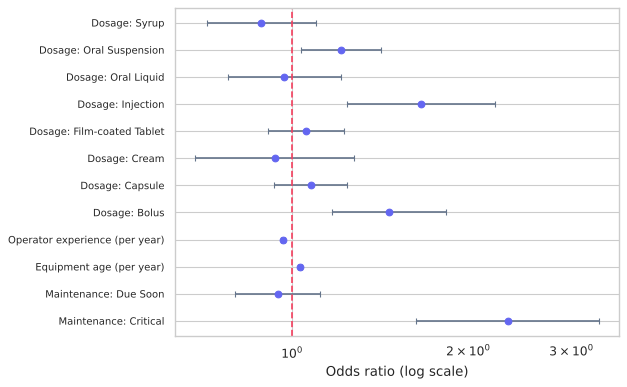

**[Multivariate] Adjusted odds ratios with equipment fixed effects (selected terms)**

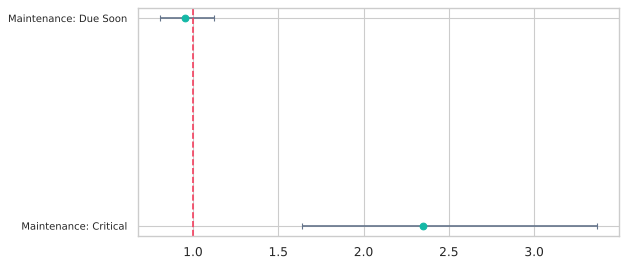

**[Bivariate] Observed against expected failures for each machine**

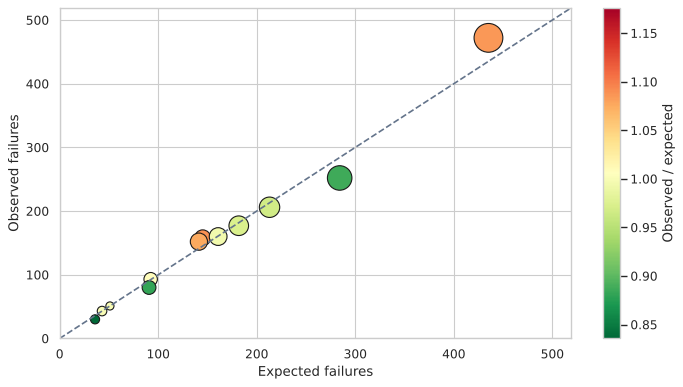

**[Univariate] Standardised failure ratio by machine, with 95% interval**

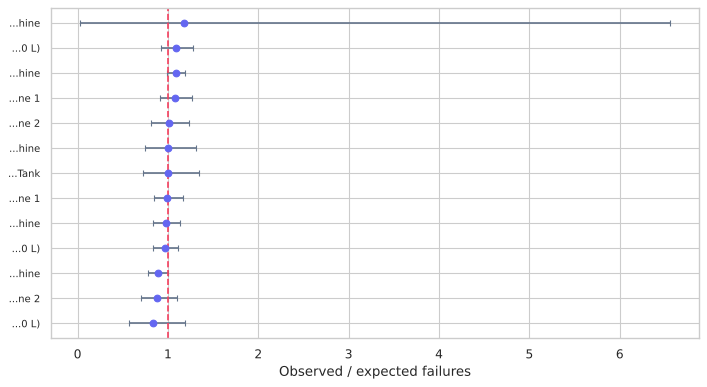

**[Bivariate] Failure rate by equipment age (years)**

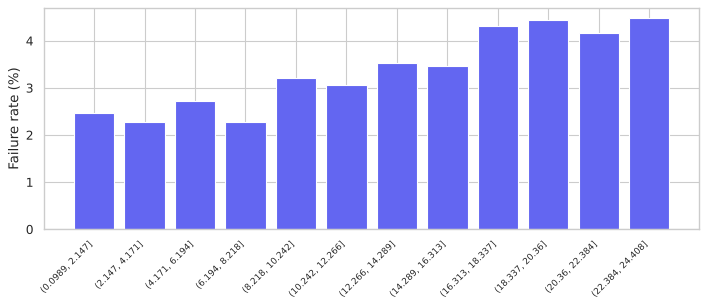

**[Univariate] Availability under three assumed repair times (equipment, scenario table)**

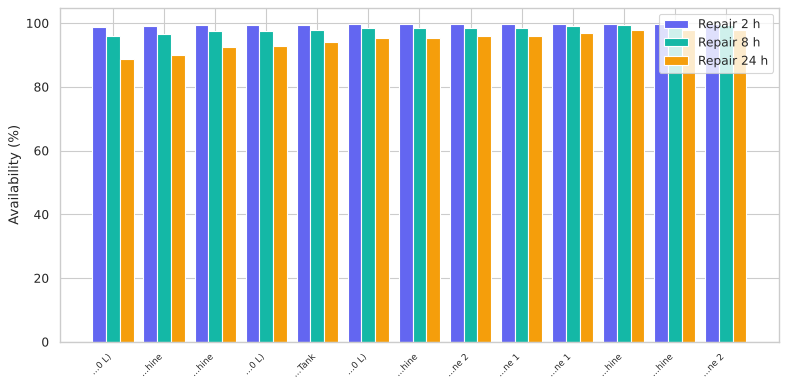

> **Summary of this section**
> - Critical maintenance has an adjusted odds ratio of 2.33 for failure; the confidence interval excludes 1.
> - 6 of 13 machines are on Watch: their observed failures are above expected and the interval includes 1.
> - Repair times are assumptions, because the data has no repair records; the availability figures are scenarios, not measurements.

In [4]:
chart("Multivariate", "Adjusted odds ratios for batch failure (maintenance, dosage, section, age, operator)")
ml = pd.read_csv(TABLES / "maintenance_logit.csv")
ml = ml[ml.term != "Intercept"]
fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(ml))
ax.errorbar(ml.odds_ratio, y, xerr=[ml.odds_ratio - ml.or_ci_low, ml.or_ci_high - ml.odds_ratio], fmt="o", color=PAL[0], ecolor="#64748B", capsize=3)
ax.axvline(1, color=PAL[5], ls="--")
ax.set_yticks(y); ax.set_yticklabels(ml.term, fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("Odds ratio (log scale)")
plt.tight_layout(); plt.show()

chart("Multivariate", "Adjusted odds ratios with equipment fixed effects (selected terms)")
mfe = pd.read_csv(TABLES / "maintenance_logit_equipment_fe.csv")
mfe = mfe[mfe.term.str.contains("maint|Maint|Critical|Due", regex=True)]
fig, ax = plt.subplots(figsize=(8, 3.5))
y = np.arange(len(mfe))
ax.errorbar(mfe.odds_ratio, y, xerr=[mfe.odds_ratio - mfe.or_ci_low, mfe.or_ci_high - mfe.odds_ratio], fmt="o", color=PAL[1], ecolor="#64748B", capsize=3)
ax.axvline(1, color=PAL[5], ls="--")
ax.set_yticks(y); ax.set_yticklabels(mfe.term, fontsize=9)
plt.tight_layout(); plt.show()

eq = pd.read_csv(TABLES / "equipment_reliability.csv")
chart("Bivariate", "Observed against expected failures for each machine")
fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(eq.expected_failures, eq.failures, yerr=None, fmt="none")
sc = ax.scatter(eq.expected_failures, eq.failures, s=eq.batches / 20, c=eq.standardised_ratio, cmap="RdYlGn_r", edgecolor="k")
lim = [0, max(eq.expected_failures.max(), eq.failures.max()) * 1.1]
ax.plot(lim, lim, ls="--", color="#64748B"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Expected failures"); ax.set_ylabel("Observed failures")
plt.colorbar(sc, label="Observed / expected")
plt.tight_layout(); plt.show()

chart("Univariate", "Standardised failure ratio by machine, with 95% interval")
e = eq.sort_values("standardised_ratio").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(e))
ax.errorbar(e.standardised_ratio, y, xerr=[e.standardised_ratio - e.ratio_ci_low, e.ratio_ci_high - e.standardised_ratio], fmt="o", color=PAL[0], ecolor="#64748B", capsize=3)
ax.axvline(1, color=PAL[5], ls="--")
ax.set_yticks(y); ax.set_yticklabels([mask(n) for n in e.equipment_name], fontsize=9)
ax.set_xlabel("Observed / expected failures")
plt.tight_layout(); plt.show()

chart("Bivariate", "Failure rate by equipment age (years)")
age = batches.groupby(pd.cut(batches.equipment_age_years, bins=12)).batch_failed.agg(["mean", "size"]).reset_index()
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(np.arange(len(age)), age["mean"] * 100, color=PAL[0])
ax.set_xticks(np.arange(len(age))); ax.set_xticklabels([str(i) for i in age.equipment_age_years], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Failure rate (%)"); plt.tight_layout(); plt.show()

chart("Univariate", "Availability under three assumed repair times (equipment, scenario table)")
av = pd.read_csv(TABLES / "availability_scenarios.csv")
av = av.sort_values("availability_if_repair_8h")
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(av)); w = 0.27
for i, (col, lab) in enumerate([("availability_if_repair_2h", "2 h"), ("availability_if_repair_8h", "8 h"), ("availability_if_repair_24h", "24 h")]):
    ax.bar(x + (i - 1) * w, av[col] * 100, w, label=f"Repair {lab}", color=PAL[i])
ax.set_xticks(x); ax.set_xticklabels([mask(n) for n in av.equipment_name], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Availability (%)"); ax.legend(); plt.tight_layout(); plt.show()

summary([
    f"Critical maintenance has an adjusted odds ratio of {ml.loc[ml.term.str.contains('Critical'), 'odds_ratio'].iloc[0]:.2f} for failure; the confidence interval excludes 1.",
    f"{int(eq.priority.str.startswith('Watch').sum())} of {len(eq)} machines are on Watch: their observed failures are above expected and the interval includes 1.",
    "Repair times are assumptions, because the data has no repair records; the availability figures are scenarios, not measurements.",
])

## 3. Classifier and predictor

Test period: recall 0.819, precision 0.040, ROC-AUC 0.581, batches flagged 75.1%


**[Bivariate] ROC curve on the 2024 to 2026 test period**

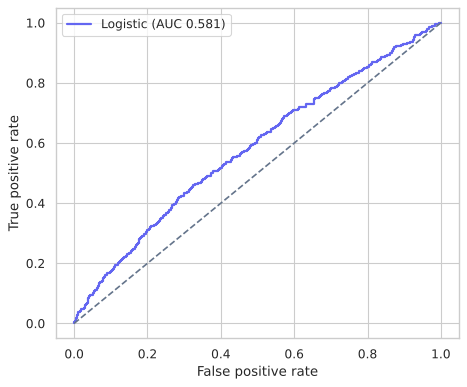

**[Bivariate] Precision-recall curve on the test period**

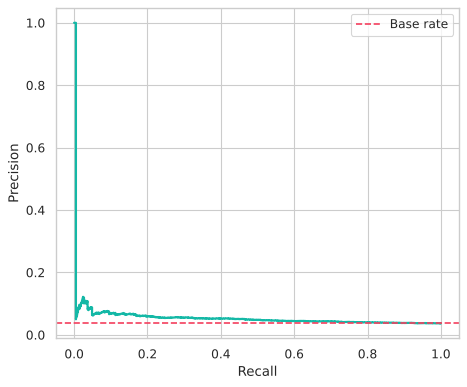

**[Univariate] Confusion matrix at the adopted threshold (test period)**

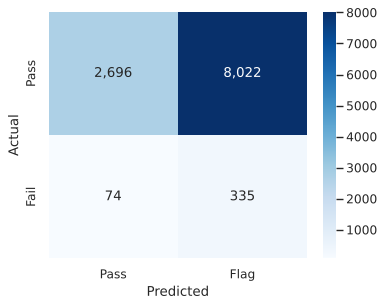

**[Bivariate] Calibration: predicted against observed failure rate by decile (test period)**

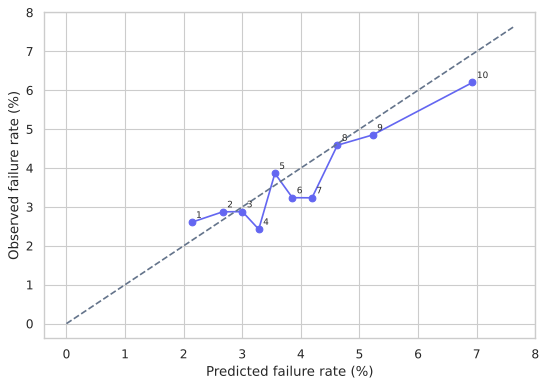

**[Univariate] Failure rate by predicted-risk decile (lift over the base rate)**

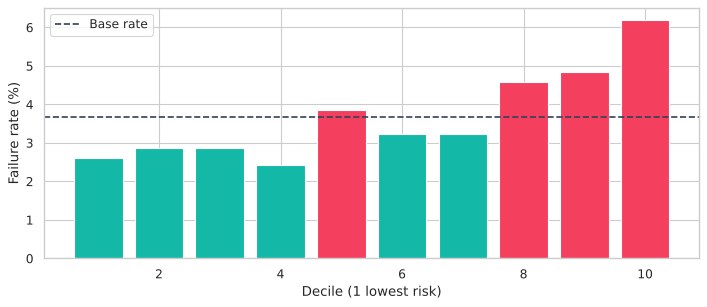

**[Univariate] Permutation importance (drop in ROC-AUC when a feature is shuffled)**

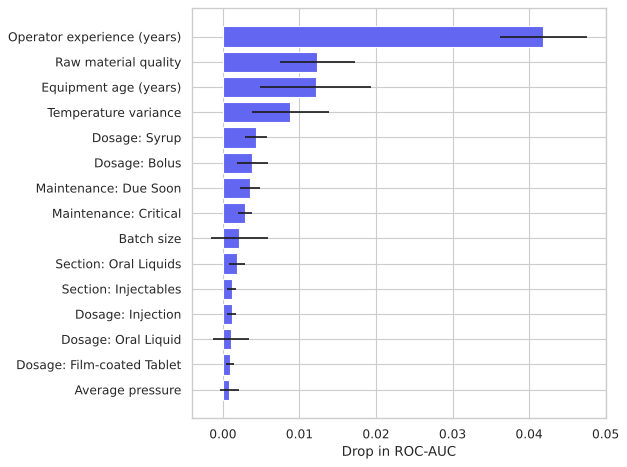

**[Multivariate] Model comparison on validation and test: recall, precision and ROC-AUC**

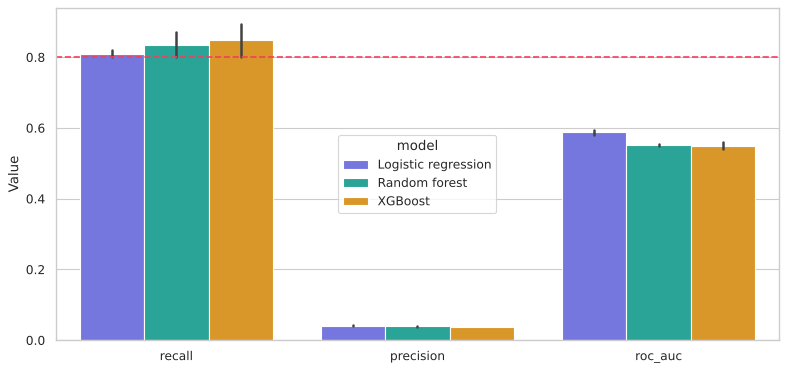

In [5]:
splits = modeling.split_by_time(batches)
test_idx = splits["test"]
spec = predictor
X_all = features.build_design(batches)
cols = spec["columns"]
assert list(X_all[cols].columns) == cols, "design columns differ from the exported model"
Z = (X_all[cols].astype(float).fillna(pd.Series(spec["imputer_median"], index=cols)) - np.array(spec["scaler_mean"])) / np.array(spec["scaler_scale"])
raw_score = spec["intercept"] + Z.values @ np.array(spec["coefficients"])
cal = spec["calibration"]
prob = 1 / (1 + np.exp(-(cal["slope"] * raw_score + cal["intercept"])))
raw_prob = 1 / (1 + np.exp(-raw_score))
y_test = batches.loc[test_idx, "batch_failed"].values
p_test, r_test = prob[batches.index.get_indexer(test_idx)], raw_prob[batches.index.get_indexer(test_idx)]
flag_test = r_test >= spec["threshold_raw"]
tp = int(((flag_test == 1) & (y_test == 1)).sum()); fp = int(((flag_test == 1) & (y_test == 0)).sum())
fn = int(((flag_test == 0) & (y_test == 1)).sum()); tn = int(((flag_test == 0) & (y_test == 0)).sum())
recall, precision = tp / (tp + fn), tp / (tp + fp)
fpr, tpr, _ = roc_curve(y_test, r_test); roc_auc = auc(fpr, tpr)
print(f"Test period: recall {recall:.3f}, precision {precision:.3f}, ROC-AUC {roc_auc:.3f}, batches flagged {flag_test.mean():.1%}")

chart("Bivariate", "ROC curve on the 2024 to 2026 test period")
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, color=PAL[0], lw=2, label=f"Logistic (AUC {roc_auc:.3f})")
ax.plot([0, 1], [0, 1], ls="--", color="#64748B"); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.legend(); plt.tight_layout(); plt.show()

chart("Bivariate", "Precision-recall curve on the test period")
pr, rc, _ = precision_recall_curve(y_test, r_test)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(rc, pr, color=PAL[1], lw=2); ax.axhline(y_test.mean(), ls="--", color=PAL[5], label="Base rate")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.legend(); plt.tight_layout(); plt.show()

chart("Univariate", "Confusion matrix at the adopted threshold (test period)")
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(np.array([[tn, fp], [fn, tp]]), annot=True, fmt=",", cmap="Blues", xticklabels=["Pass", "Flag"], yticklabels=["Pass", "Fail"], ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); plt.tight_layout(); plt.show()

chart("Bivariate", "Calibration: predicted against observed failure rate by decile (test period)")
dec = pd.DataFrame({"p": p_test, "y": y_test})
dec["decile"] = pd.qcut(dec.p.rank(method="first"), 10, labels=range(1, 11)).astype(int)
dd = dec.groupby("decile").agg(pred=("p", "mean"), obs=("y", "mean")).reset_index()
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(dd.pred * 100, dd.obs * 100, "o-", color=PAL[0])
lim = max(dd.pred.max(), dd.obs.max()) * 110
ax.plot([0, lim], [0, lim], ls="--", color="#64748B")
for _, r in dd.iterrows(): ax.annotate(int(r.decile), (r.pred * 100, r.obs * 100), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("Predicted failure rate (%)"); ax.set_ylabel("Observed failure rate (%)")
plt.tight_layout(); plt.show()

chart("Univariate", "Failure rate by predicted-risk decile (lift over the base rate)")
fig, ax = plt.subplots(figsize=(9, 4))
obs_rate = dd.obs * 100
ax.bar(dd.decile, obs_rate, color=[PAL[1] if v < y_test.mean() * 100 else PAL[5] for v in obs_rate])
ax.axhline(y_test.mean() * 100, ls="--", color="#334155", label="Base rate"); ax.legend()
ax.set_xlabel("Decile (1 lowest risk)"); ax.set_ylabel("Failure rate (%)"); plt.tight_layout(); plt.show()

chart("Univariate", "Permutation importance (drop in ROC-AUC when a feature is shuffled)")
pi = pd.read_csv(TABLES / "permutation_importance.csv").sort_values("importance_mean").tail(15)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(pi.label, pi.importance_mean, xerr=pi.importance_std, color=PAL[0])
ax.set_xlabel("Drop in ROC-AUC"); plt.tight_layout(); plt.show()

chart("Multivariate", "Model comparison on validation and test: recall, precision and ROC-AUC")
vm = pd.read_csv(TABLES / "validation_metrics.csv"); tm = pd.read_csv(TABLES / "test_metrics.csv")
mc = pd.concat([vm.assign(period="Validation"), tm.assign(period="Test")])
mc["model"] = mc.model.str.split(" \\(").str[0]
mm = mc.melt(id_vars=["model", "period"], value_vars=["recall", "precision", "roc_auc"], var_name="metric", value_name="value")
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.barplot(data=mm, x="metric", y="value", hue="model", palette=PAL, ax=ax)
ax.axhline(0.80, ls="--", color=PAL[5]); ax.set_ylabel("Value"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

**[Multivariate] Predicted failure chance for a typical batch and for batches with one change**

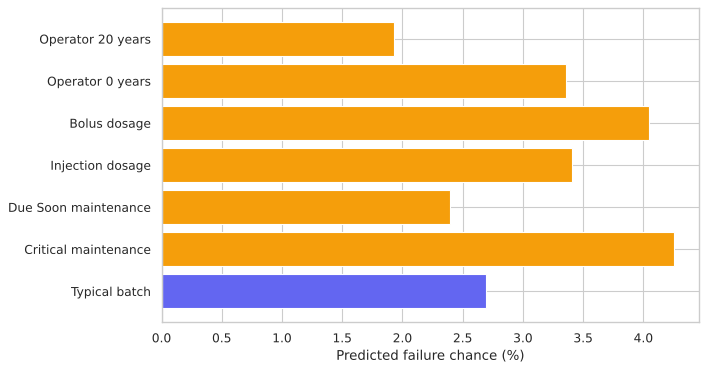

**[Bivariate] Predicted failure chance as average temperature varies (other inputs typical)**

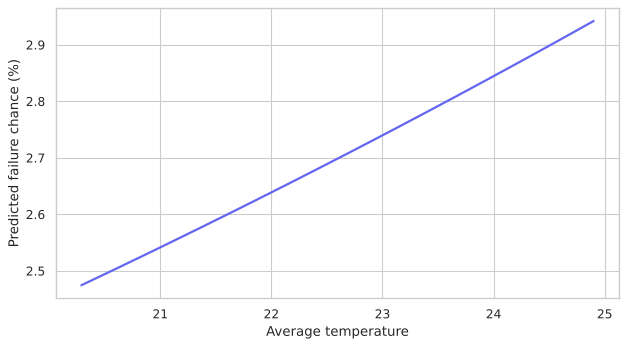

**[Bivariate] Predicted failure chance as temperature variance varies**

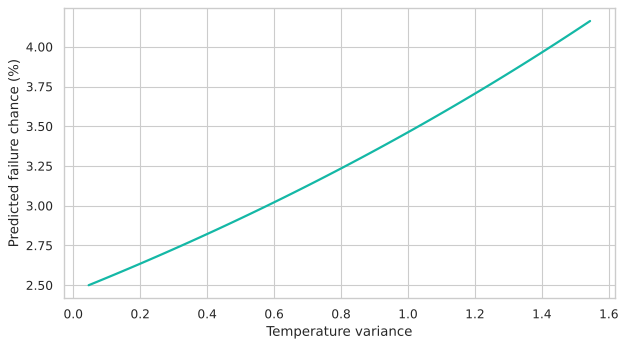

**[Multivariate] Factor contributions for one example batch against a typical batch**

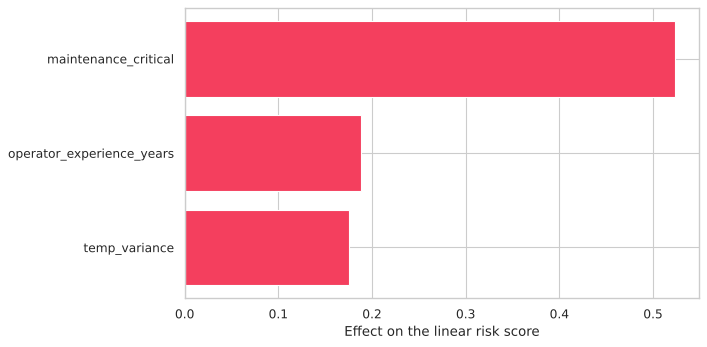

> **Summary of this section**
> - On the test period the adopted logistic model has recall 0.819 (target 0.80) and precision 0.040 (target 0.19); ROC-AUC 0.581 (target 0.80).
> - A typical batch has a predicted failure chance of 2.69%; Critical maintenance raises it to 4.25%.
> - The predictor is calibrated, so its probabilities match observed rates by decile. Its spread is narrow, so it is a triage aid, not a release decision.

In [6]:
chart("Multivariate", "Predicted failure chance for a typical batch and for batches with one change")
typ = pd.Series({i["name"]: i["typical"] for i in spec["inputs"]["numeric"]})
def chance_for(changes):
    x = pd.Series(0.0, index=cols)
    for c in features.NUMERIC_FEATURES: x[c] = typ[c]
    for k, v in changes.items(): x[k] = v
    zz = (x - np.array(spec["scaler_mean"])) / np.array(spec["scaler_scale"])
    rs = spec["intercept"] + float(zz.values @ np.array(spec["coefficients"]))
    return 1 / (1 + np.exp(-(cal["slope"] * rs + cal["intercept"])))
base_p = chance_for({})
scen = {
    "Typical batch": {},
    "Critical maintenance": {"maintenance_critical": 1.0},
    "Due Soon maintenance": {"maintenance_due_soon": 1.0},
    "Injection dosage": {"dosage_Injection": 1.0},
    "Bolus dosage": {"dosage_Bolus": 1.0},
    "Operator 0 years": {"operator_experience_years": 0.0},
    "Operator 20 years": {"operator_experience_years": 20.0},
}
sc_p = {k: chance_for(v) for k, v in scen.items()}
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(list(sc_p.keys()), [v * 100 for v in sc_p.values()], color=[PAL[0] if k == "Typical batch" else PAL[2] for k in sc_p])
ax.set_xlabel("Predicted failure chance (%)"); plt.tight_layout(); plt.show()

chart("Bivariate", "Predicted failure chance as average temperature varies (other inputs typical)")
temps = np.linspace(batches.temp_avg.quantile(0.01), batches.temp_avg.quantile(0.99), 60)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(temps, [chance_for({"temp_avg": t}) * 100 for t in temps], color=PAL[0], lw=2)
ax.set_xlabel("Average temperature"); ax.set_ylabel("Predicted failure chance (%)"); plt.tight_layout(); plt.show()

chart("Bivariate", "Predicted failure chance as temperature variance varies")
vars_ = np.linspace(batches.temp_variance.quantile(0.01), batches.temp_variance.quantile(0.99), 60)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(vars_, [chance_for({"temp_variance": v}) * 100 for v in vars_], color=PAL[1], lw=2)
ax.set_xlabel("Temperature variance"); ax.set_ylabel("Predicted failure chance (%)"); plt.tight_layout(); plt.show()

chart("Multivariate", "Factor contributions for one example batch against a typical batch")
example = {"maintenance_critical": 1.0, "temp_variance": float(batches.temp_variance.quantile(0.9)), "operator_experience_years": 2.0}
def contrib(changes):
    x_typ = pd.Series(0.0, index=cols)
    for c in features.NUMERIC_FEATURES: x_typ[c] = typ[c]
    x_ex = x_typ.copy()
    for k, v in changes.items(): x_ex[k] = v
    zt = (x_typ - np.array(spec["scaler_mean"])) / np.array(spec["scaler_scale"])
    ze = (x_ex - np.array(spec["scaler_mean"])) / np.array(spec["scaler_scale"])
    return pd.Series(np.array(spec["coefficients"]) * (ze.values - zt.values), index=cols)
ct = contrib(example)
ct = ct[ct.abs() > 1e-4].sort_values()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(ct.index, ct.values, color=[PAL[5] if v > 0 else PAL[1] for v in ct.values])
ax.axvline(0, color="#334155"); ax.set_xlabel("Effect on the linear risk score")
plt.tight_layout(); plt.show()

summary([
    f"On the test period the adopted logistic model has recall {recall:.3f} (target 0.80) and precision {precision:.3f} (target 0.19); ROC-AUC {roc_auc:.3f} (target 0.80).",
    f"A typical batch has a predicted failure chance of {pct(base_p, 2)}; Critical maintenance raises it to {pct(sc_p['Critical maintenance'], 2)}.",
    "The predictor is calibrated, so its probabilities match observed rates by decile. Its spread is narrow, so it is a triage aid, not a release decision.",
])

## 4. Process control

**[Univariate] Share of readings inside control limits, by variable**

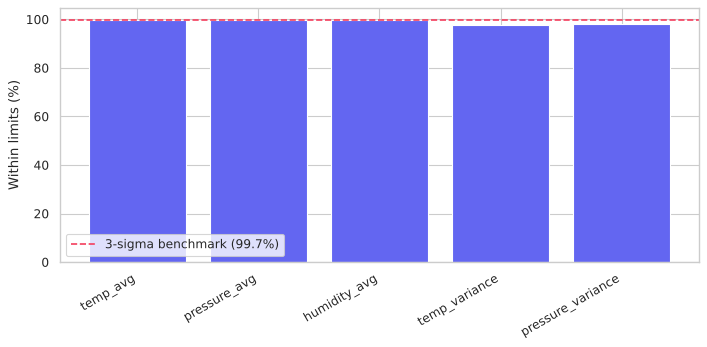

**[Univariate] Out-of-control readings by variable**

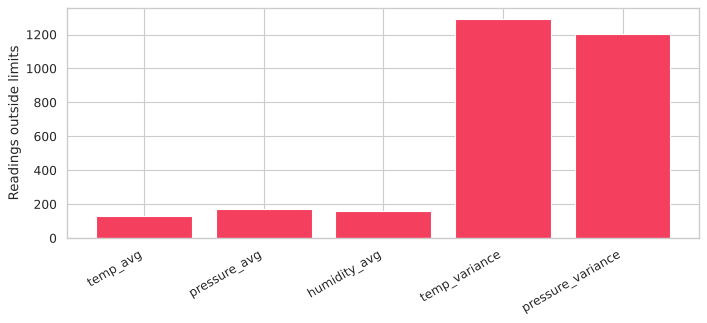

**[Univariate] Individuals chart: assay_result_purity in section Creams & Ointments (first 300 batches)**

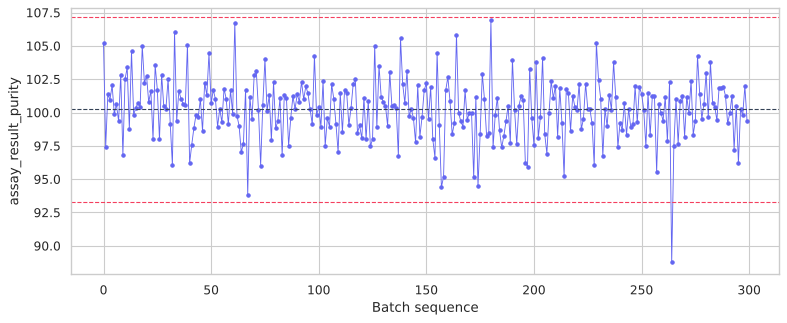

**[Univariate] Process capability (Cpk) by manufacturing section against 1.33**

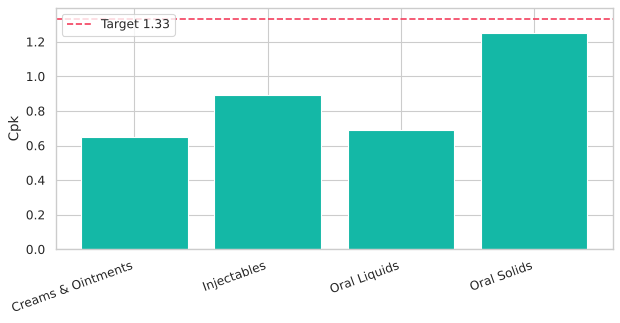

**[Bivariate] Out-of-spec share against Cpk by section**

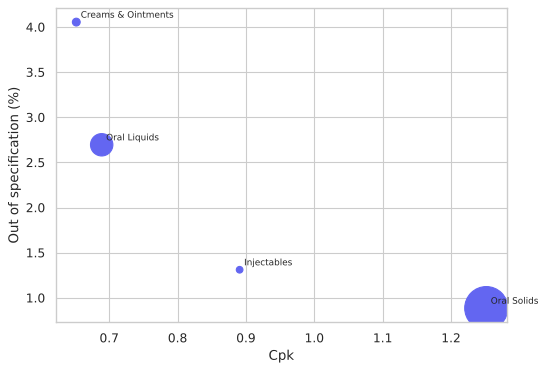

> **Summary of this section**
> - Within-limits shares range from 97.8% to 99.8% across variables.
> - The lowest Cpk is 0.65 and the highest 1.25; 0 of 4 sections meet the 1.33 target.

In [7]:
cl = pd.read_csv(TABLES / "control_limits.csv")
wl = pd.read_csv(TABLES / "within_limits.csv")
chart("Univariate", "Share of readings inside control limits, by variable")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(wl.variable, wl.share_within_limits * 100, color=PAL[0])
ax.axhline(99.7, ls="--", color=PAL[5], label="3-sigma benchmark (99.7%)"); ax.legend()
ax.set_ylabel("Within limits (%)"); plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
plt.tight_layout(); plt.show()

chart("Univariate", "Out-of-control readings by variable")
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(wl.variable, wl.readings_out_of_control, color=PAL[5])
ax.set_ylabel("Readings outside limits"); plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
plt.tight_layout(); plt.show()

section = cl.manufacturing_section.iloc[0]
var = "assay_result_purity" if "assay_result_purity" in batches.columns else "temp_avg"
row = cl[(cl.manufacturing_section == section)]
chart("Univariate", f"Individuals chart: {var} in section {section} (first 300 batches)")
s_ = batches.loc[batches.manufacturing_section == section, var].head(300).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(s_, marker=".", lw=0.8, color=PAL[0])
mu = s_.mean(); sd = s_.std()
for lvl, col in [(mu, "#334155"), (mu + 3 * sd, PAL[5]), (mu - 3 * sd, PAL[5])]:
    ax.axhline(lvl, color=col, ls="--", lw=1)
ax.set_xlabel("Batch sequence"); ax.set_ylabel(var)
plt.tight_layout(); plt.show()

cap = pd.read_csv(TABLES / "capability.csv")
chart("Univariate", "Process capability (Cpk) by manufacturing section against 1.33")
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(cap.manufacturing_section, cap.cpk, color=PAL[1])
ax.axhline(1.33, ls="--", color=PAL[5], label="Target 1.33"); ax.legend(); ax.set_ylabel("Cpk")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right"); plt.tight_layout(); plt.show()

chart("Bivariate", "Out-of-spec share against Cpk by section")
fig, ax = plt.subplots(figsize=(7, 4.8))
ax.scatter(cap.cpk, cap.share_out_of_spec * 100, s=cap.n / 30, color=PAL[0])
for _, r in cap.iterrows(): ax.annotate(r.manufacturing_section, (r.cpk, r.share_out_of_spec * 100), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("Cpk"); ax.set_ylabel("Out of specification (%)")
plt.tight_layout(); plt.show()

summary([
    f"Within-limits shares range from {pct(wl.share_within_limits.min())} to {pct(wl.share_within_limits.max())} across variables.",
    f"The lowest Cpk is {cap.cpk.min():.2f} and the highest {cap.cpk.max():.2f}; {int((cap.cpk >= 1.33).sum())} of {len(cap)} sections meet the 1.33 target.",
])

## 5. Receivables

**[Univariate] Open credit balance by age band**

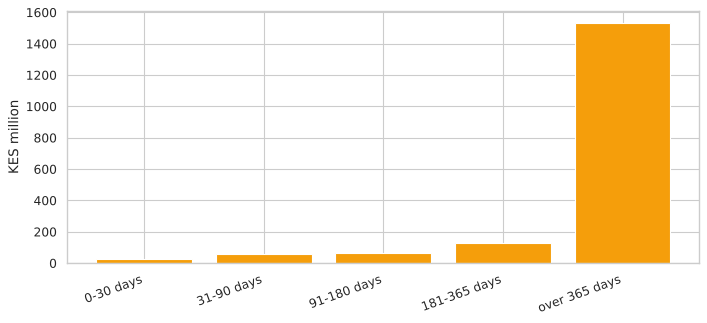

**[Univariate] Invoices by age band**

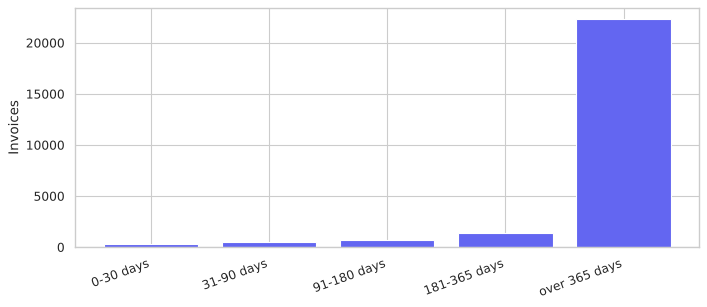

**[Bivariate] Share of credit invoices still open, by sale year**

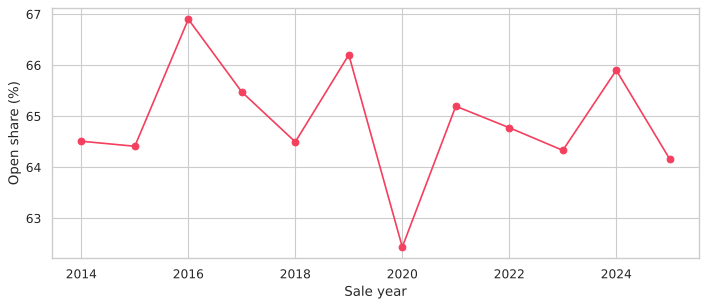

**[Multivariate] Open balance by age band and sale year (credit invoices)**

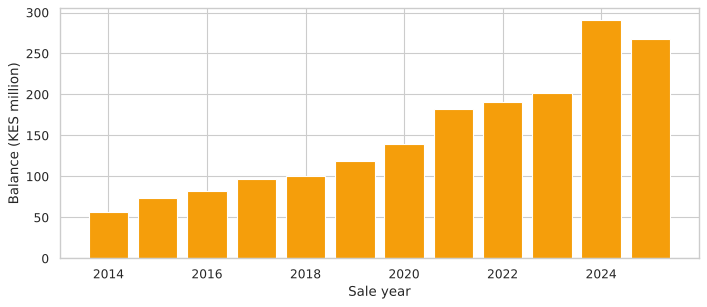

> **Summary of this section**
> - Open credit totals KES 1,804 million; 85.1% is older than a year.
> - The open share is 64% in the latest sale year, flat across years: the balance field probably does not record payments, so collection lists stay closed.

In [8]:
ageing = pd.read_csv(TABLES / "credit_ageing.csv")
share = pd.read_csv(TABLES / "credit_open_share.csv")
chart("Univariate", "Open credit balance by age band")
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(ageing.bucket, ageing.open_balance_KES / 1e6, color=PAL[2])
ax.set_ylabel("KES million"); plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
plt.tight_layout(); plt.show()

chart("Univariate", "Invoices by age band")
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(ageing.bucket, ageing.invoices, color=PAL[0])
plt.setp(ax.get_xticklabels(), rotation=20, ha="right"); ax.set_ylabel("Invoices")
plt.tight_layout(); plt.show()

chart("Bivariate", "Share of credit invoices still open, by sale year")
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(share.year, share.open_share * 100, "o-", color=PAL[5])
ax.set_xlabel("Sale year"); ax.set_ylabel("Open share (%)"); plt.tight_layout(); plt.show()

chart("Multivariate", "Open balance by age band and sale year (credit invoices)")
cr = sales[commercial.is_credit(sales)].copy()
cr["bal"] = cr["Balance_Due_KES"].fillna(0)
piv = cr.pivot_table(index="year", values="bal", aggfunc="sum") / 1e6
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(piv.index.astype(int), piv.bal, color=PAL[2])
ax.set_xlabel("Sale year"); ax.set_ylabel("Balance (KES million)"); plt.tight_layout(); plt.show()

over_year = ageing.loc[ageing.bucket == "over 365 days", "open_balance_KES"].iloc[0] / ageing.open_balance_KES.sum()
summary([
    f"Open credit totals KES {ageing.open_balance_KES.sum()/1e6:,.0f} million; {pct(over_year)} is older than a year.",
    f"The open share is {pct(share.open_share.iloc[-1], 0)} in the latest sale year, flat across years: the balance field probably does not record payments, so collection lists stay closed.",
])

## 6. Margin and discounts

**[Bivariate] Gross margin and number of orders by discount level**

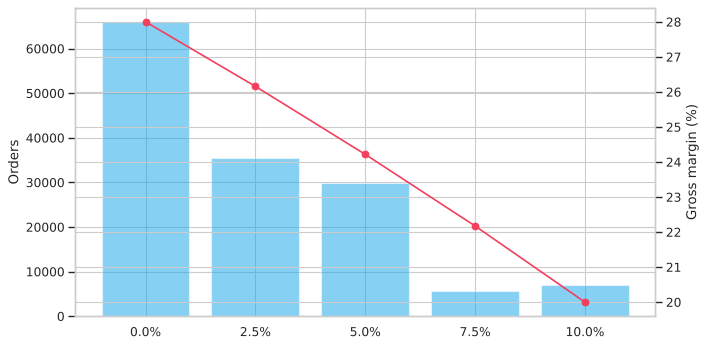

**[Bivariate] Units ordered against discount (3,000 random live orders, log scale)**

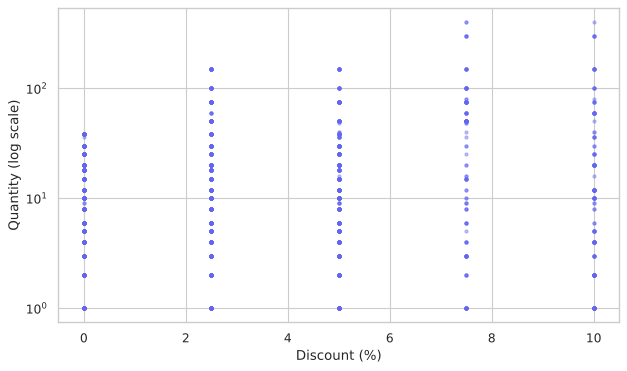

**[Univariate] Distribution of discount levels on live orders**

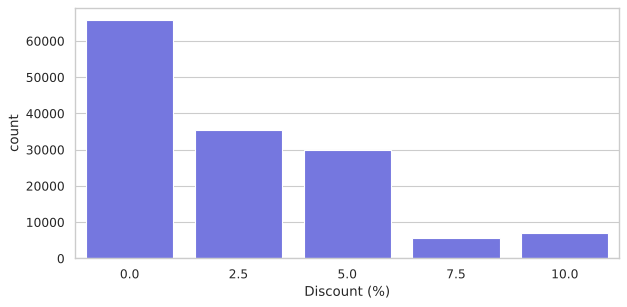

**[Bivariate] Units response per discount point: full period against 2014 to 2023 (95% interval)**

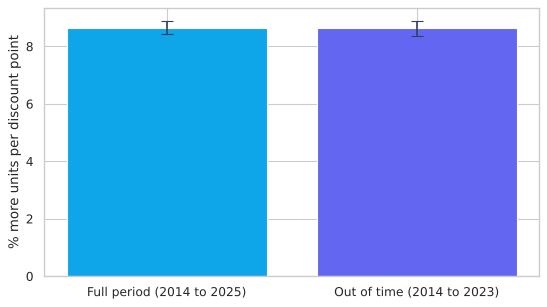

**[Univariate] Profit change from the 5% cap, 2024 and 2025, by volume case**

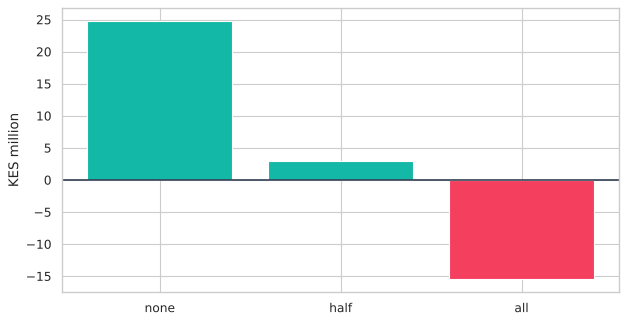

**[Multivariate] Volume retained and profit change by volume case**

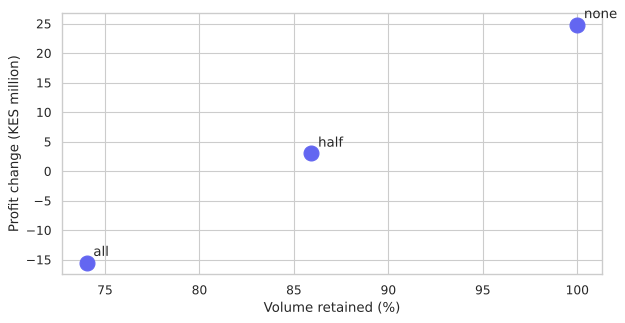

> **Summary of this section**
> - Gross margin falls from 28.0% at no discount to 20.0% at the deepest discount.
> - Out of time, each discount point adds 8.64% units (2014 to 2023 estimate); the full-period estimate is 8.65%.
> - A 5% cap changes 2024 and 2025 profit by KES 24.8 million with no volume loss and KES -15.5 million if all of the volume response is lost.

In [9]:
margin = commercial.margin_by_discount(sales)
chart("Bivariate", "Gross margin and number of orders by discount level")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(margin.Discount_Pct.astype(str) + "%", margin.orders, color=PAL[4], alpha=0.5, label="Orders")
ax2 = ax.twinx(); ax2.plot(margin.Discount_Pct.astype(str) + "%", margin.gross_margin_pct, "o-", color=PAL[5], label="Gross margin (%)")
ax.set_ylabel("Orders"); ax2.set_ylabel("Gross margin (%)")
plt.tight_layout(); plt.show()

live = commercial.live_orders(sales)
chart("Bivariate", "Units ordered against discount (3,000 random live orders, log scale)")
samp = live.sample(min(3000, len(live)), random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(samp.Discount_Pct, samp.Quantity, s=8, alpha=0.4, color=PAL[0])
ax.set_yscale("log"); ax.set_xlabel("Discount (%)"); ax.set_ylabel("Quantity (log scale)")
plt.tight_layout(); plt.show()

chart("Univariate", "Distribution of discount levels on live orders")
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(x=live.Discount_Pct, color=PAL[0], ax=ax); ax.set_xlabel("Discount (%)")
plt.tight_layout(); plt.show()

vol_full = commercial.discount_volume_model(sales)
vol_out = commercial.discount_volume_model(sales, max_year=config.VALIDATION_END_YEAR)
chart("Bivariate", "Units response per discount point: full period against 2014 to 2023 (95% interval)")
fig, ax = plt.subplots(figsize=(7, 4))
labels = ["Full period (2014 to 2025)", "Out of time (2014 to 2023)"]
vals = [vol_full["pct_per_point"], vol_out["pct_per_point"]]
lo = [vol_full["pct_low"], vol_out["pct_low"]]; hi = [vol_full["pct_high"], vol_out["pct_high"]]
ax.bar(labels, vals, color=[PAL[4], PAL[0]])
ax.errorbar(labels, vals, yerr=[np.array(vals) - np.array(lo), np.array(hi) - np.array(vals)], fmt="none", ecolor="#334155", capsize=5)
ax.set_ylabel("% more units per discount point"); plt.tight_layout(); plt.show()

scen = commercial.discount_cap_scenarios(sales, coef=vol_out["coef_log_per_point"], years=(2024, 2025))
chart("Univariate", "Profit change from the 5% cap, 2024 and 2025, by volume case")
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(scen.assumption, scen.profit_change_KES / 1e6, color=[PAL[1] if v >= 0 else PAL[5] for v in scen.profit_change_KES])
ax.axhline(0, color="#334155"); ax.set_ylabel("KES million")
plt.tight_layout(); plt.show()

chart("Multivariate", "Volume retained and profit change by volume case")
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(scen.volume_retained_pct, scen.profit_change_KES / 1e6, s=180, color=PAL[0])
for _, r in scen.iterrows(): ax.annotate(r.assumption, (r.volume_retained_pct, r.profit_change_KES / 1e6), xytext=(6, 6), textcoords="offset points")
ax.set_xlabel("Volume retained (%)"); ax.set_ylabel("Profit change (KES million)")
plt.tight_layout(); plt.show()

summary([
    f"Gross margin falls from {pct(margin.gross_margin_pct.iloc[0]/100)} at no discount to {pct(margin.gross_margin_pct.iloc[-1]/100)} at the deepest discount.",
    f"Out of time, each discount point adds {vol_out['pct_per_point']:.2f}% units (2014 to 2023 estimate); the full-period estimate is {vol_full['pct_per_point']:.2f}%.",
    f"A 5% cap changes 2024 and 2025 profit by KES {scen.profit_change_KES.iloc[0]/1e6:.1f} million with no volume loss and KES {scen.profit_change_KES.iloc[2]/1e6:.1f} million if all of the volume response is lost.",
])

## 7. Inventory and forecast

**[Univariate] Forecast error on the 2025 holdout by method (WAPE, lower is better)**

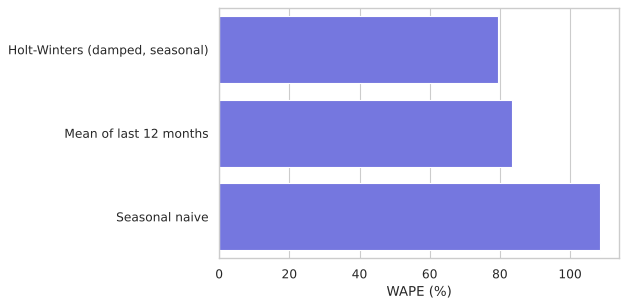

**[Bivariate] Monthly demand: actual against chosen forecast and seasonal naive (60 series)**

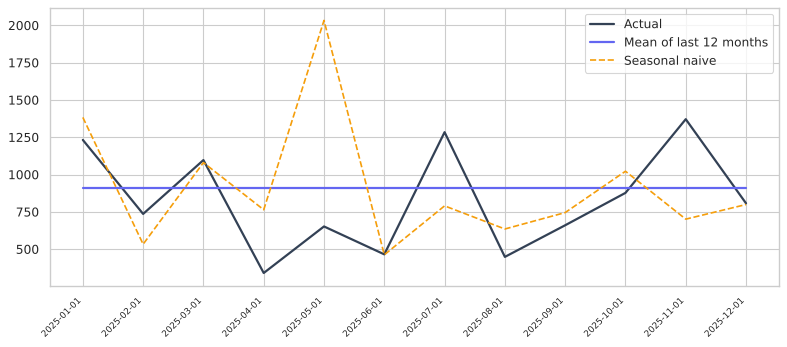

**[Bivariate] Forecast error by series: chosen method against seasonal naive**

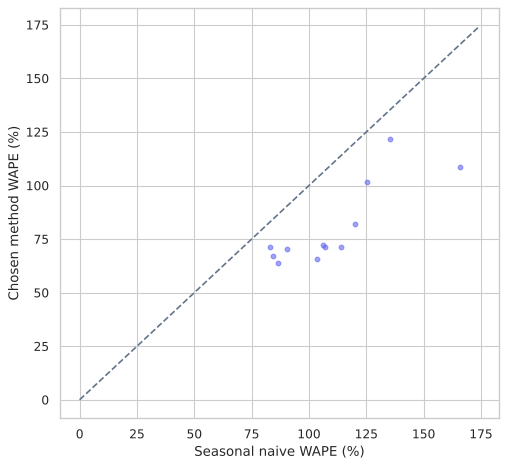

**[Univariate] Cancelled stock value by product: top 20 (Pareto)**

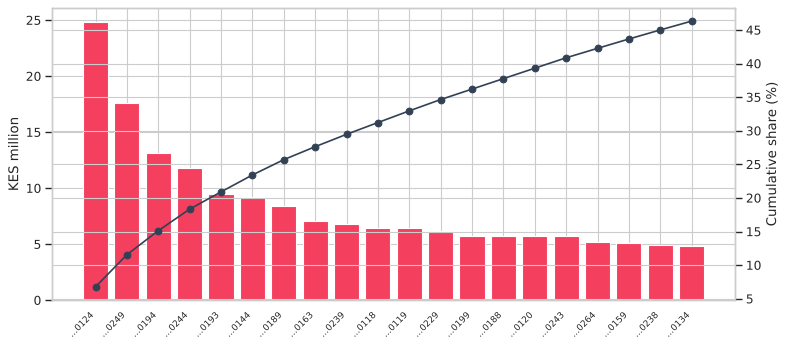

**[Univariate] Reorder point at 30 days lead time**

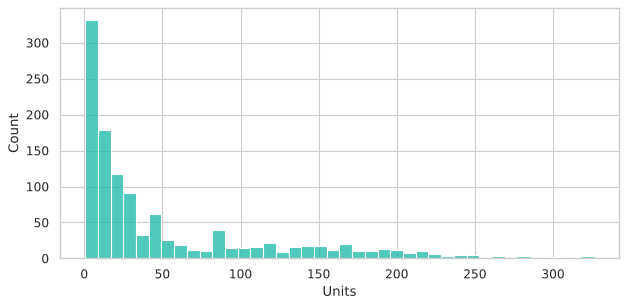

**[Bivariate] Monthly mean demand against reorder point at 60 days**

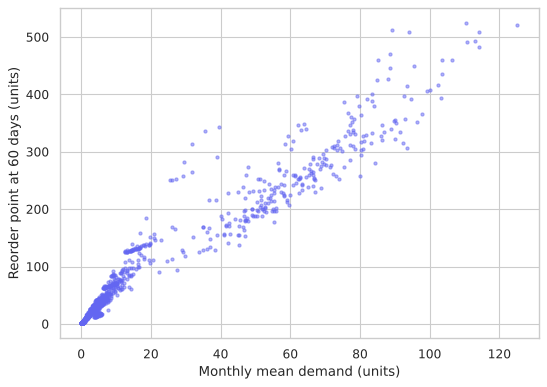

**[Bivariate] Estimated opening stock against its upper bound**

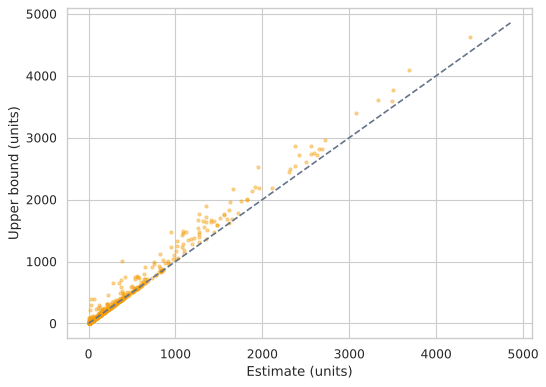

> **Summary of this section**
> - On the 2025 holdout the chosen method (mean of last 12 months) has WAPE 83.6%, against 108.6% for seasonal naive. Holt-Winters has a lower WAPE but was not chosen under the 2024 selection rule.
> - Cancelled stock worth KES 367.7 million; the top five products hold 21% of it.

In [10]:
fh = pd.read_csv(TABLES / "forecast_holdout.csv")
chart("Univariate", "Forecast error on the 2025 holdout by method (WAPE, lower is better)")
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=fh.wape_pct, y=fh.method, color=PAL[0], ax=ax); ax.set_xlabel("WAPE (%)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

paths = pd.read_csv(TABLES / "forecast_paths_holdout.csv")
mon = paths.groupby("month")[["actual", "forecast_chosen", "forecast_seasonal_naive"]].sum().reset_index()
chart("Bivariate", "Monthly demand: actual against chosen forecast and seasonal naive (60 series)")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(mon.month, mon.actual, color="#334155", lw=2, label="Actual")
ax.plot(mon.month, mon.forecast_chosen, color=PAL[0], lw=2, label="Mean of last 12 months")
ax.plot(mon.month, mon.forecast_seasonal_naive, color=PAL[2], ls="--", label="Seasonal naive")
ax.legend(); plt.setp(ax.get_xticklabels(), rotation=45, ha="right", fontsize=8)
plt.tight_layout(); plt.show()

chart("Bivariate", "Forecast error by series: chosen method against seasonal naive")
ps = paths.groupby(["Branch_Code", "Product_ID"]).apply(lambda d: pd.Series({
    "a": d.actual.sum(), "c": (d.actual - d.forecast_chosen).abs().sum(), "n": (d.actual - d.forecast_seasonal_naive).abs().sum()})).reset_index()
ps["wape_chosen"] = ps.c / ps.a * 100; ps["wape_naive"] = ps.n / ps.a * 100
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(ps.wape_naive, ps.wape_chosen, s=18, alpha=0.6, color=PAL[0])
lim = max(ps.wape_naive.max(), ps.wape_chosen.max()) * 1.05
ax.plot([0, lim], [0, lim], ls="--", color="#64748B"); ax.set_xlabel("Seasonal naive WAPE (%)"); ax.set_ylabel("Chosen method WAPE (%)")
plt.tight_layout(); plt.show()

canc = pd.read_csv(TABLES / "cancelled_stock_outflows.csv")
pareto = canc.groupby("Product_ID").value_KES.sum().sort_values(ascending=False).head(20)
chart("Univariate", "Cancelled stock value by product: top 20 (Pareto)")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar([mask(p) for p in pareto.index], pareto.values / 1e6, color=PAL[5])
ax2 = ax.twinx(); ax2.plot([mask(p) for p in pareto.index], pareto.cumsum().values / canc.value_KES.sum() * 100, "o-", color="#334155")
ax.set_ylabel("KES million"); ax2.set_ylabel("Cumulative share (%)")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", fontsize=8)
plt.tight_layout(); plt.show()

rp = pd.read_csv(TABLES / "reorder_points.csv")
chart("Univariate", "Reorder point at 30 days lead time")
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(rp.reorder_point_30d, bins=40, color=PAL[1], ax=ax); ax.set_xlabel("Units")
plt.tight_layout(); plt.show()

chart("Bivariate", "Monthly mean demand against reorder point at 60 days")
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(rp.monthly_mean, rp.reorder_point_60d, s=8, alpha=0.5, color=PAL[0])
ax.set_xlabel("Monthly mean demand (units)"); ax.set_ylabel("Reorder point at 60 days (units)")
plt.tight_layout(); plt.show()

ops = pd.read_csv(TABLES / "opening_stock_range.csv")
chart("Bivariate", "Estimated opening stock against its upper bound")
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(ops.opening_stock_units, ops.opening_stock_units_upper, s=8, alpha=0.4, color=PAL[2])
lim = ops.opening_stock_units_upper.max() * 1.05
ax.plot([0, lim], [0, lim], ls="--", color="#64748B")
ax.set_xlabel("Estimate (units)"); ax.set_ylabel("Upper bound (units)")
plt.tight_layout(); plt.show()

summary([
    f"On the 2025 holdout the chosen method ({summary_json['forecast']['chosen_method'].lower()}) has WAPE {fh.loc[fh.method == summary_json['forecast']['chosen_method'], 'wape_pct'].iloc[0]:.1f}%, against {fh.loc[fh.method.str.contains('naive', case=False), 'wape_pct'].iloc[0]:.1f}% for seasonal naive. Holt-Winters has a lower WAPE but was not chosen under the 2024 selection rule.",
    f"Cancelled stock worth KES {canc.value_KES.sum()/1e6:,.1f} million; the top five products hold {pct(pareto.head(5).sum()/canc.value_KES.sum(), 0)} of it.",
])

## 8. Cost and suppliers

**[Bivariate] Median unit cost of goods received, by year**

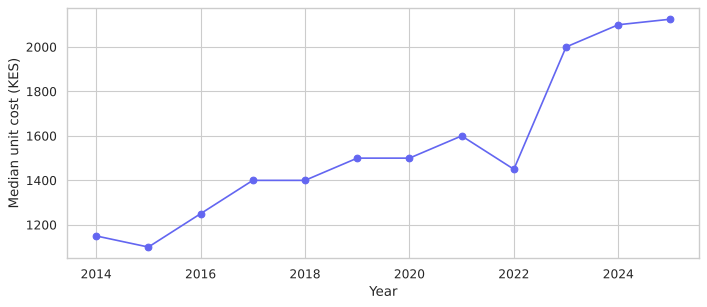

**[Univariate] Distribution of supplier premium over the reference price**

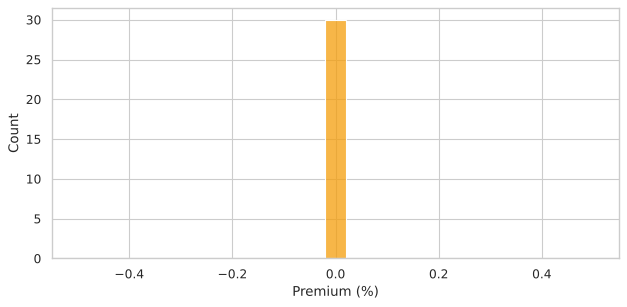

**[Bivariate] Receipts against premium by supplier**

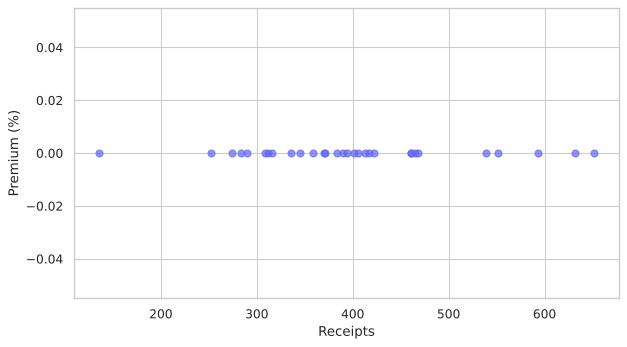

**[Bivariate] Supplier concentration (HHI) by year, with the 1,500 threshold**

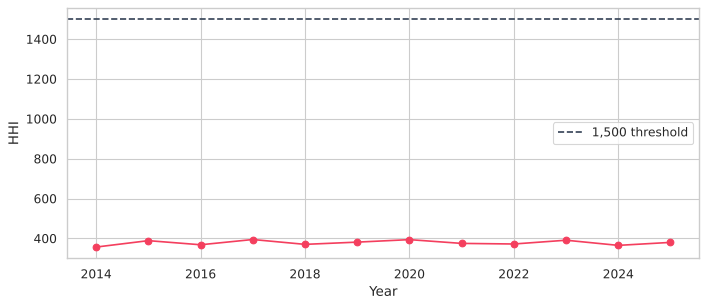

**[Multivariate] Pass-through of cost changes to price, by product category, with 95% interval**

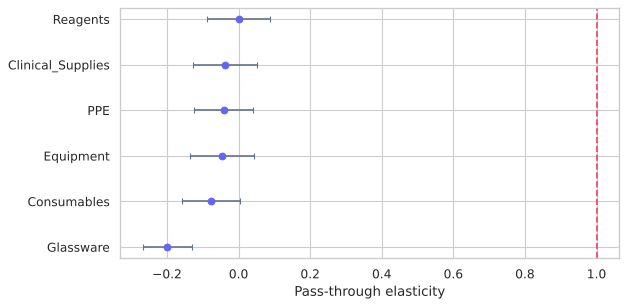

> **Summary of this section**
> - Median unit cost of goods received rose from KES 1,150 in 2014 to KES 2,125 in 2025.
> - The latest supplier concentration (HHI) is 380, below the 1,500 threshold.
> - 0 of 30 suppliers charge above the reference price; the premium is zero for every supplier, so no supplier premium is found in the data.

In [11]:
gr = inventory[inventory.Movement_Type == "Goods_Received"]
chart("Bivariate", "Median unit cost of goods received, by year")
uc = gr.groupby("year").Unit_Cost_KES.median().reset_index()
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(uc.year, uc.Unit_Cost_KES, "o-", color=PAL[0])
ax.set_xlabel("Year"); ax.set_ylabel("Median unit cost (KES)"); plt.tight_layout(); plt.show()

chart("Univariate", "Distribution of supplier premium over the reference price")
sp = pd.read_csv(TABLES / "supplier_premium.csv")
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(sp.premium_pct, bins=25, color=PAL[2], ax=ax); ax.set_xlabel("Premium (%)")
plt.tight_layout(); plt.show()

chart("Bivariate", "Receipts against premium by supplier")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(sp.receipts, sp.premium_pct, s=40, color=PAL[0], alpha=0.7)
ax.set_xlabel("Receipts"); ax.set_ylabel("Premium (%)"); plt.tight_layout(); plt.show()

hhi = pd.read_csv(TABLES / "supplier_concentration.csv")
chart("Bivariate", "Supplier concentration (HHI) by year, with the 1,500 threshold")
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(hhi.year, hhi.hhi, "o-", color=PAL[5]); ax.axhline(1500, ls="--", color="#334155", label="1,500 threshold"); ax.legend()
ax.set_xlabel("Year"); ax.set_ylabel("HHI"); plt.tight_layout(); plt.show()

pt = pd.read_csv(TABLES / "pass_through_by_category.csv")
chart("Multivariate", "Pass-through of cost changes to price, by product category, with 95% interval")
fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(pt))
ax.errorbar(pt.elasticity, y, xerr=[pt.elasticity - pt.low, pt.high - pt.elasticity], fmt="o", color=PAL[0], ecolor="#64748B", capsize=3)
ax.axvline(1, ls="--", color=PAL[5]); ax.set_yticks(y); ax.set_yticklabels(pt.category)
ax.set_xlabel("Pass-through elasticity")
plt.tight_layout(); plt.show()

summary([
    f"Median unit cost of goods received rose from KES {uc.Unit_Cost_KES.iloc[0]:,.0f} in {int(uc.year.iloc[0])} to KES {uc.Unit_Cost_KES.iloc[-1]:,.0f} in {int(uc.year.iloc[-1])}.",
    f"The latest supplier concentration (HHI) is {hhi.hhi.iloc[-1]:,.0f}, {'above' if hhi.hhi.iloc[-1] >= 1500 else 'below'} the 1,500 threshold.",
    f"{int((sp.premium_pct > 0).sum())} of {len(sp)} suppliers charge above the reference price; the premium is zero for every supplier, so no supplier premium is found in the data.",
])

## 9. Risk score and rule backtest

**[Bivariate] Alert rules: share of batches flagged against share of failures caught**

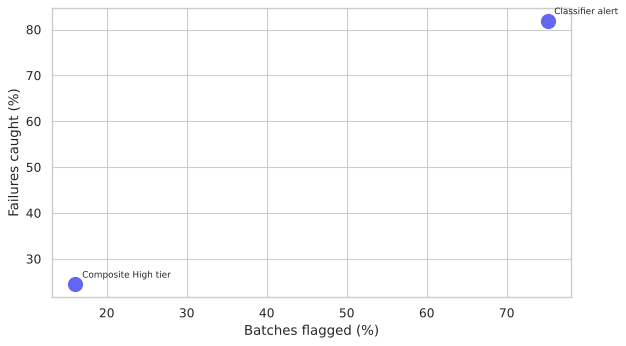

**[Multivariate] Risk weight sensitivity: batches flagged and failures caught by weighting**

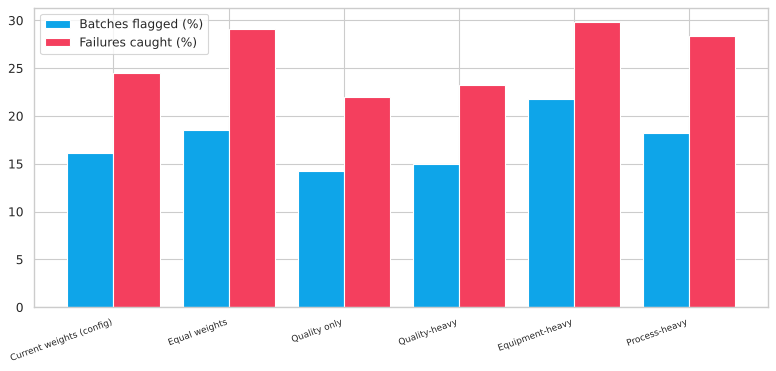

**[Multivariate] Weights in each scenario (quality, equipment, process)**

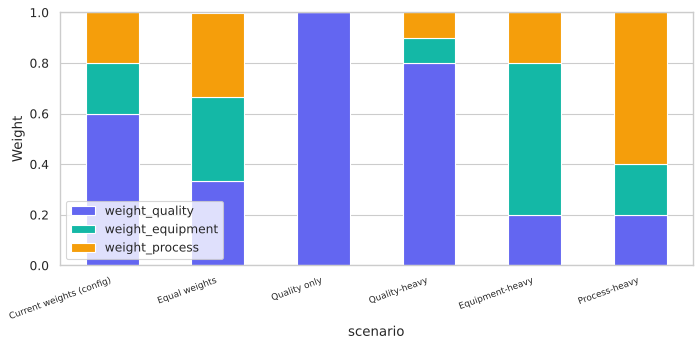

> **Summary of this section**
> - The classifier rule catches 82% of failures from 75% of batches (rule: Classifier alert).
> - The weights are assumptions. The sensitivity chart shows how the flagged set changes with them, so they need a decision before the score is used.

In [12]:
bt = pd.read_csv(TABLES / "risk_backtest.csv")
bt_cl = bt[bt.rule.str.contains("lass", case=False)]
bt_cl = bt_cl if len(bt_cl) else bt.iloc[[0]]
chart("Bivariate", "Alert rules: share of batches flagged against share of failures caught")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(bt.share_of_batches_flagged * 100, bt.share_of_failures_caught * 100, s=160, color=PAL[0])
for _, r in bt.iterrows(): ax.annotate(r.rule, (r.share_of_batches_flagged * 100, r.share_of_failures_caught * 100), xytext=(6, 6), textcoords="offset points", fontsize=8)
ax.set_xlabel("Batches flagged (%)"); ax.set_ylabel("Failures caught (%)")
plt.tight_layout(); plt.show()

ws = pd.read_csv(TABLES / "risk_weight_sensitivity.csv")
chart("Multivariate", "Risk weight sensitivity: batches flagged and failures caught by weighting")
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(ws)); w = 0.4
ax.bar(x - w / 2, ws.share_of_batches_flagged * 100, w, label="Batches flagged (%)", color=PAL[4])
ax.bar(x + w / 2, ws.share_of_failures_caught * 100, w, label="Failures caught (%)", color=PAL[5])
ax.set_xticks(x); ax.set_xticklabels(ws.scenario, rotation=20, ha="right", fontsize=8); ax.legend()
plt.tight_layout(); plt.show()

chart("Multivariate", "Weights in each scenario (quality, equipment, process)")
wt = ws.set_index("scenario")[["weight_quality", "weight_equipment", "weight_process"]]
fig, ax = plt.subplots(figsize=(9, 4.5))
wt.plot(kind="bar", stacked=True, color=PAL[:3], ax=ax); ax.set_ylabel("Weight")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right", fontsize=8)
plt.tight_layout(); plt.show()

summary([
    f"The classifier rule catches {pct(bt_cl.share_of_failures_caught.iloc[0], 0)} of failures from {pct(bt_cl.share_of_batches_flagged.iloc[0], 0)} of batches (rule: {bt_cl.rule.iloc[0]}).",
    "The weights are assumptions. The sensitivity chart shows how the flagged set changes with them, so they need a decision before the score is used.",
])

## 10. Consistency check against the dashboard

The notebook recomputes figures that the dashboard shows, and records whether they agree. The result is written to `reports/notebook_check.json`, which the dashboard reads.

,item,notebook,dashboard,agree
0,Batch failure rate (%),3.125000,3.120000,True
1,"Test recall, adopted classifier",0.819071,0.819071,True
2,"Test ROC-AUC, adopted classifier",0.581213,0.581213,True
3,"Calibration, decile 10 predicted (%)",6.928557,6.930000,True
4,"Units per discount point, 2014 to 2023 (%)",8.638362,8.638362,True
5,"Profit change, no volume loss, 2024 and 2025 (...",24.823555,24.823555,True
6,"Profit change, all volume lost, 2024 and 2025 ...",-15.488537,-15.488537,True
7,Forecast gain over seasonal naive (%),23.018083,23.018083,True


**[Univariate] Agreement between this notebook and the dashboard**

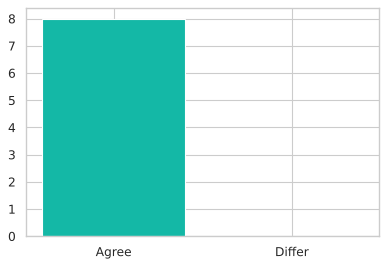

> **Summary of this section**
> - 8 of 8 checked figures agree with the dashboard within a stated tolerance.

In [13]:
checks = []
def check(item, notebook_value, dashboard_value, tol):
    ok = bool(abs(notebook_value - dashboard_value) <= tol)
    checks.append({"item": item, "notebook": round(float(notebook_value), 6), "dashboard": round(float(dashboard_value), 6), "agree": ok})

dash = json.loads((ROOT / "dashboard" / "public" / "data" / "dashboard.json").read_text(encoding="utf-8"))
dsum = dash["summary"]
dash_scen = {r["assumption"]: r for r in dash["tables"]["discount_cap_scenarios"]}
dash_logit = [r for r in dsum["classifier"]["test"] if r["model"].startswith("Logistic")][0]
fc_chosen = fh.loc[fh.method == summary_json["forecast"]["chosen_method"], "wape_pct"].iloc[0]
fc_naive = fh.loc[fh.method.str.contains("naive", case=False), "wape_pct"].iloc[0]

check("Batch failure rate (%)", batches.batch_failed.mean() * 100, dsum["failure_rate_pct"], 0.01)
check("Test recall, adopted classifier", recall, dash_logit["recall"], 0.001)
check("Test ROC-AUC, adopted classifier", roc_auc, dash_logit["roc_auc"], 0.001)
check("Calibration, decile 10 predicted (%)", dd.pred.iloc[-1] * 100, predictor["calibration_check"][-1]["predicted"] * 100, 0.01)
check("Units per discount point, 2014 to 2023 (%)", vol_out["pct_per_point"], dsum["discount"]["fitted_to_validation_end"]["pct_per_point"], 0.01)
check("Profit change, no volume loss, 2024 and 2025 (KES m)", scen.profit_change_KES.iloc[0] / 1e6, dash_scen["none"]["profit_change_KES"] / 1e6, 0.01)
check("Profit change, all volume lost, 2024 and 2025 (KES m)", scen.profit_change_KES.iloc[2] / 1e6, dash_scen["all"]["profit_change_KES"] / 1e6, 0.01)
check("Forecast gain over seasonal naive (%)", (fc_naive - fc_chosen) / fc_naive * 100, dsum["forecast"]["improvement_vs_seasonal_naive_pct"], 0.05)

check_table = pd.DataFrame(checks)
display(check_table)
agree_n, total_n = int(check_table.agree.sum()), len(check_table)
(REPORTS / "notebook_check.json").write_text(json.dumps({"agree": agree_n, "total": total_n, "checks": checks}, indent=2), encoding="utf-8")
chart("Univariate", "Agreement between this notebook and the dashboard")
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["Agree", "Differ"], [agree_n, total_n - agree_n], color=[PAL[1], PAL[5]])
plt.tight_layout(); plt.show()
summary([f"{agree_n} of {total_n} checked figures agree with the dashboard within a stated tolerance."])